# 03. The test problems

`jaxglobal.problems` collects standard nonconvex test functions, each written
as an ordinary JAX function of one array `x`: no modelling language, no
equations, no special operators. This notebook shows what they look like,
solves all of them to a certified gap, and checks how hard they are for two
simpler methods: plain interval arithmetic and a local-solver multistart.

Most of the unconstrained functions are from the Virtual Library of
Simulation Experiments [surjanovic2013virtual]; the constrained ones are
from the CEC 2006 suite [liang2006problem] and the process-design literature
[haverly1978studies, ryoo1995global].

In [1]:
import os
import pathlib
import sys

os.environ.setdefault("RUST_LOG", "warn")  # keep the local NLP solver's info messages out of the output
ROOT = pathlib.Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT))

import inspect
import json

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize as sp_minimize

from jaxglobal import interval, minimize
from jaxglobal.problems import CONSTRAINED_PROBLEMS, PROBLEMS

INK, MUTED, BLUE, ORANGE, AQUA, YELLOW = "#1a1a19", "#77766f", "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.6, "figure.dpi": 110})
P = {p.name: p for p in PROBLEMS}
C = {p.name: p for p in CONSTRAINED_PROBLEMS}

## How a problem is written

A problem is the Python function, a box $[\ell, u]$, and the known optimum
$f^*$ from the literature (or `None` when there is none). For example, the
Eggholder function

$$ f(x,y) = -(y+47)\sin\sqrt{\left|\tfrac{x}{2}+y+47\right|} \;-\; x\sin\sqrt{|x-(y+47)|}, \qquad (x,y)\in[-512,512]^2, $$

with its nested `abs` and `sqrt`, is just:

In [2]:
print(inspect.getsource(P["eggholder"].f))

def eggholder(x):
    a, b = x[0], x[1]
    return -(b + 47) * jnp.sin(jnp.sqrt(jnp.abs(a / 2 + b + 47))) - a * jnp.sin(
        jnp.sqrt(jnp.abs(a - (b + 47)))
    )



The other functions are written the same way. Some use features that
equation-based modelling languages handle badly or not at all:
`piecewise_2d` uses `jnp.where`, `abs` and `max`; `tanh_net_2d` is a small
neural network with fixed random weights, $f(x) = W_2^\top \tanh(W_1^\top x + b_1)$;
`shubert` and `michalewicz` build sums with `jnp.arange`.

## Solving everything

Each problem is solved with the same settings: absolute tolerance $10^{-5}$
and relative tolerance $10^{-6}$ on the gap $U-L$. Two extra columns show why
the problems are not easy:

* **root LB**: the natural interval bound on the whole box, $\underline{f}([\ell,u])$.
  If it were close to $f^*$ the problem would be nearly trivial for any
  bounding method.
* **multistart**: the fraction of 20 L-BFGS-B runs from random starting
  points that reach $f^*$ (to $10^{-4}$ relative). A low number means many
  local minima that trap a local solver.

In [3]:
def multistart(p, fstar, n=20, seed=0):
    rng = np.random.default_rng(seed)
    vg = jax.jit(jax.value_and_grad(p.f))
    ends = []
    for _ in range(n):
        r = sp_minimize(lambda x: tuple(np.asarray(v) for v in vg(x)), rng.uniform(p.lo, p.hi),
                        jac=True, method="L-BFGS-B", bounds=list(zip(p.lo, p.hi)))
        ends.append((r.x, r.fun))
    hits = np.mean([fx <= fstar + 1e-4 * max(1, abs(fstar)) for _, fx in ends])
    return hits, ends


results, ends = {}, {}
rows = []
for p in PROBLEMS:
    r = minimize(p.f, p.lo, p.hi, abs_tol=1e-5, rel_tol=1e-6, max_iter=4000)
    results[p.name] = r
    fstar = p.fstar if p.fstar is not None else r.fun
    hits, ends[p.name] = multistart(p, fstar)
    rows.append(dict(problem=p.name, n=p.lo.size, f_lit=p.fstar, f_found=r.fun, L=r.lower_bound,
                     gap=r.gap, root_LB=float(interval(p.f)(jnp.asarray(p.lo), jnp.asarray(p.hi))[0]),
                     multistart=hits, nodes=r.nodes, time_s=r.time, status=r.status))
table = pd.DataFrame(rows).set_index("problem")
table.style.format({"f_lit": "{:.6f}", "f_found": "{:.6f}", "L": "{:.6f}", "gap": "{:.1e}",
                    "root_LB": "{:.3g}", "multistart": "{:.0%}", "time_s": "{:.1f}"}, na_rep="—")

,n,f_lit,f_found,L,gap,root_LB,multistart,nodes,time_s,status
problem,,,,,,,,,,
gramacy_lee,1,-0.869011,-0.869011,-0.869011,9.0e-12,-1,15%,5,2.4,optimal
six_hump_camel,2,-1.031628,-1.031628,-1.031632,3.4e-06,-156,95%,21,2.3,optimal
mccormick,2,-1.913223,-1.913223,-1.913224,1.2e-06,-13.5,55%,11,1.1,optimal
goldstein_price,2,3.000000,3.000000,2.999998,2.4e-06,-8.79e+07,60%,1441,2.9,optimal
shubert,2,-186.730909,-186.730909,-186.731070,1.6e-04,-225,0%,277,2.3,optimal
michalewicz_2d,2,-1.801303,-1.801303,-1.801303,7.1e-07,-2,5%,11,2.2,optimal
holder_table,2,-19.208503,-19.208503,-19.208518,1.5e-05,-33.2,0%,279,2.4,optimal
eggholder,2,-959.640663,-959.640663,-959.640711,4.8e-05,-1.07e+03,0%,41,1.5,optimal
hartmann3,3,-3.862782,-3.862780,-3.862789,9.1e-06,-8.4,50%,91,1.6,optimal


In [4]:
ok = table.dropna(subset=["f_lit"])
err = (ok.f_found - ok.f_lit).abs() / np.maximum(1, ok.f_lit.abs())
print(f"all {len(table)} problems optimal: {(table.status == 'optimal').all()}")
print(f"largest relative deviation from the literature f*: {err.max():.1e} ({err.idxmax()})")
print(f"problems where some multistart runs miss f*: {(table.multistart < 1).sum()} of {len(table)}")

all 14 problems optimal: True
largest relative deviation from the literature f*: 6.1e-07 (hartmann3)
problems where some multistart runs miss f*: 14 of 14


Every problem closes to the requested gap, and the found values agree with the
literature to the tolerance. The root interval bounds are far below $f^*$, often
by orders of magnitude, so the solver has to work for its certificate. For
`piecewise_2d` and `tanh_net_2d` there is no published optimum; for them the
certified interval $[L, U]$ is the reference.

## A gallery of the two-dimensional problems

Contours of each 2-D function with the certified minimizer (star) and the end
points of the 20 local runs (dots). Dots away from the star are runs trapped
in a local minimum.

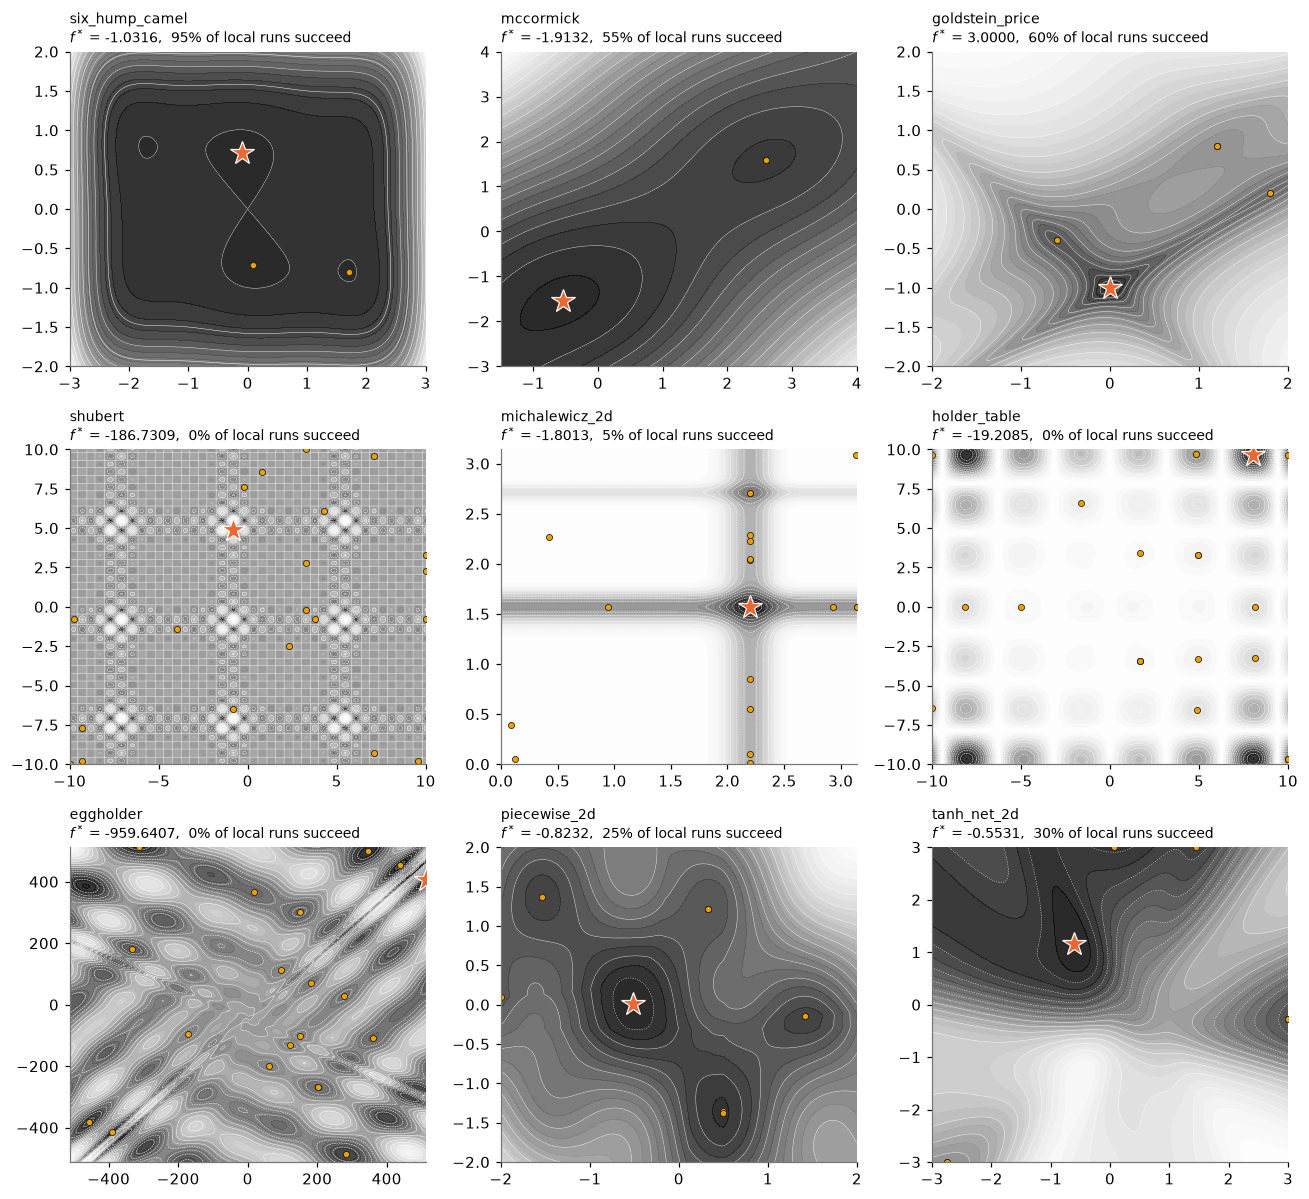

In [5]:
names = ["six_hump_camel", "mccormick", "goldstein_price", "shubert", "michalewicz_2d",
         "holder_table", "eggholder", "piecewise_2d", "tanh_net_2d"]
fig, axes = plt.subplots(3, 3, figsize=(12, 11))
for ax, name in zip(axes.ravel(), names):
    p, r = P[name], results[name]
    g1, g2 = np.linspace(p.lo[0], p.hi[0], 300), np.linspace(p.lo[1], p.hi[1], 300)
    A, B = np.meshgrid(g1, g2)
    Z = np.asarray(jax.vmap(p.f)(jnp.asarray(np.c_[A.ravel(), B.ravel()]))).reshape(A.shape)
    if name == "goldstein_price":
        Z = np.log10(Z)
    ax.contourf(A, B, Z, levels=30, cmap="Greys_r", alpha=0.85)
    ax.contour(A, B, Z, levels=15, colors="white", linewidths=0.3)
    X = np.array([x for x, _ in ends[name]])
    ax.plot(X[:, 0], X[:, 1], "o", ms=4, mfc=YELLOW, mec=INK, mew=0.5)
    ax.plot(*r.x, "*", ms=16, color=ORANGE, mec="white", mew=0.8)
    ax.set_title(f"{name}\n$f^*$ = {r.fun:.4f},  {table.multistart[name]:.0%} of local runs succeed",
                 loc="left", fontsize=9)
    ax.set_aspect("auto"); ax.grid(False)
fig.tight_layout()

A few things stand out. Shubert has 18 global minima in a regular lattice;
branch and bound returns one of them, and proves no point is better. Holder
table has its four global minima near the corners, and Eggholder has its
global minimum on the right edge of the box in a very rugged landscape; for
Shubert, Holder table and Eggholder none of the 20 local runs reaches $f^*$.
(Goldstein–Price is shown on a $\log_{10}$ scale because its values run from 3 to
about $10^6$ on the box.)

## The one-dimensional case

The Gramacy–Lee function, $f(x) = \sin(10\pi x)/(2x) + (x-1)^4$ on $[0.5, 2.5]$,
makes the trap easy to see. The histogram shows where the 20 local runs end:

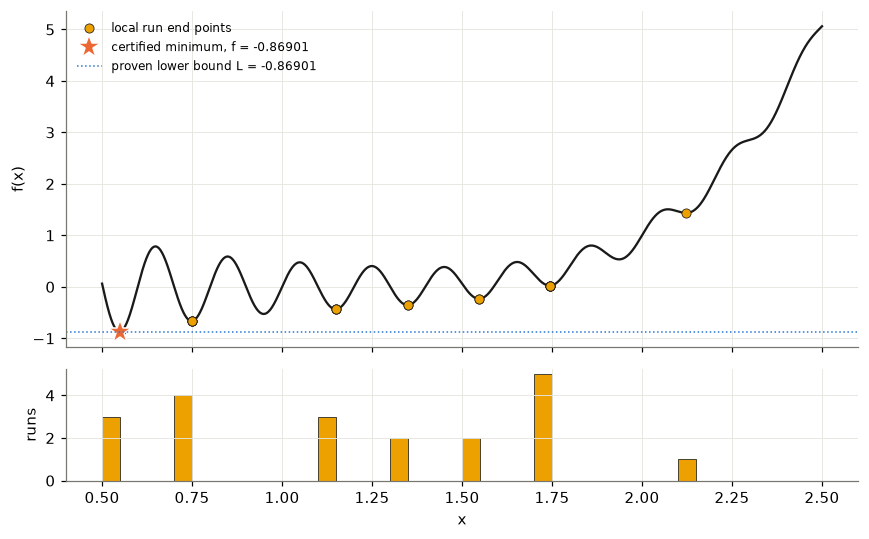

In [6]:
p, r = P["gramacy_lee"], results["gramacy_lee"]
xs = np.linspace(p.lo[0], p.hi[0], 2000)
fx = np.asarray(jax.vmap(p.f)(jnp.asarray(xs[:, None])))
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 5), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax1.plot(xs, fx, color=INK, lw=1.5)
X = np.array([x[0] for x, _ in ends["gramacy_lee"]])
ax1.plot(X, [float(p.f(jnp.array([x]))) for x in X], "o", mfc=YELLOW, mec=INK, mew=0.5, ms=6, label="local run end points")
ax1.plot(r.x[0], r.fun, "*", ms=16, color=ORANGE, mec="white", label=f"certified minimum, f = {r.fun:.5f}")
ax1.axhline(r.lower_bound, color=BLUE, ls=":", lw=1, label=f"proven lower bound L = {r.lower_bound:.5f}")
ax1.set_ylabel("f(x)"); ax1.legend(frameon=False, fontsize=8)
ax2.hist(X, bins=np.linspace(p.lo[0], p.hi[0], 41), color=YELLOW, edgecolor=INK, lw=0.5)
ax2.set_xlabel("x"); ax2.set_ylabel("runs")
fig.tight_layout()

## Constrained problems

Constraints are also plain functions: `ineq(x)` returns an array that must be
$\le 0$, and `eq(x)` an array that must be $= 0$:

$$ \min_{x\in[\ell,u]} f(x) \quad \text{s.t.} \quad g(x) \le 0,\; h(x) = 0. $$

For example, G24 has a linear objective and two quartic constraints whose
feasible set is disconnected:

In [7]:
print(inspect.getsource(C["G24"].f))
print(inspect.getsource(C["G24"].ineq))

def g24(x):
    return -x[0] - x[1]

def g24_ineq(x):
    a, b = x[0], x[1]
    return jnp.stack([
        -2 * a**4 + 8 * a**3 - 8 * a**2 + b - 2,
        -4 * a**4 + 32 * a**3 - 88 * a**2 + 96 * a + b - 36,
    ])  # fmt: skip



Lower bounds now come from relaxing the constraints as well: a box where the
convex relaxation of some $g_i$ is positive everywhere is infeasible and is
pruned, and the relaxed constraints restrict where the lower bound of $f$ is
taken. The four 2-D problems, with the infeasible region shaded and the
certified solution marked:

In [8]:
cresults = {}
crow = []
for p in CONSTRAINED_PROBLEMS:
    r = minimize(p.f, p.lo, p.hi, ineq=p.ineq, eq=p.eq, abs_tol=1e-5, rel_tol=1e-6, max_iter=4000)
    cresults[p.name] = r
    mi = 0 if p.ineq is None else np.size(p.ineq(jnp.asarray(p.lo)))
    me = 0 if p.eq is None else np.size(p.eq(jnp.asarray(p.lo)))
    crow.append(dict(problem=p.name, n=p.lo.size, ineq=mi, eq=me, f_lit=p.fstar, f_found=r.fun,
                     L=r.lower_bound, nodes=r.nodes, time_s=r.time, status=r.status,
                     verified=r.verified, max_violation=r.max_violation, note=p.note))
ctable = pd.DataFrame(crow).set_index("problem")

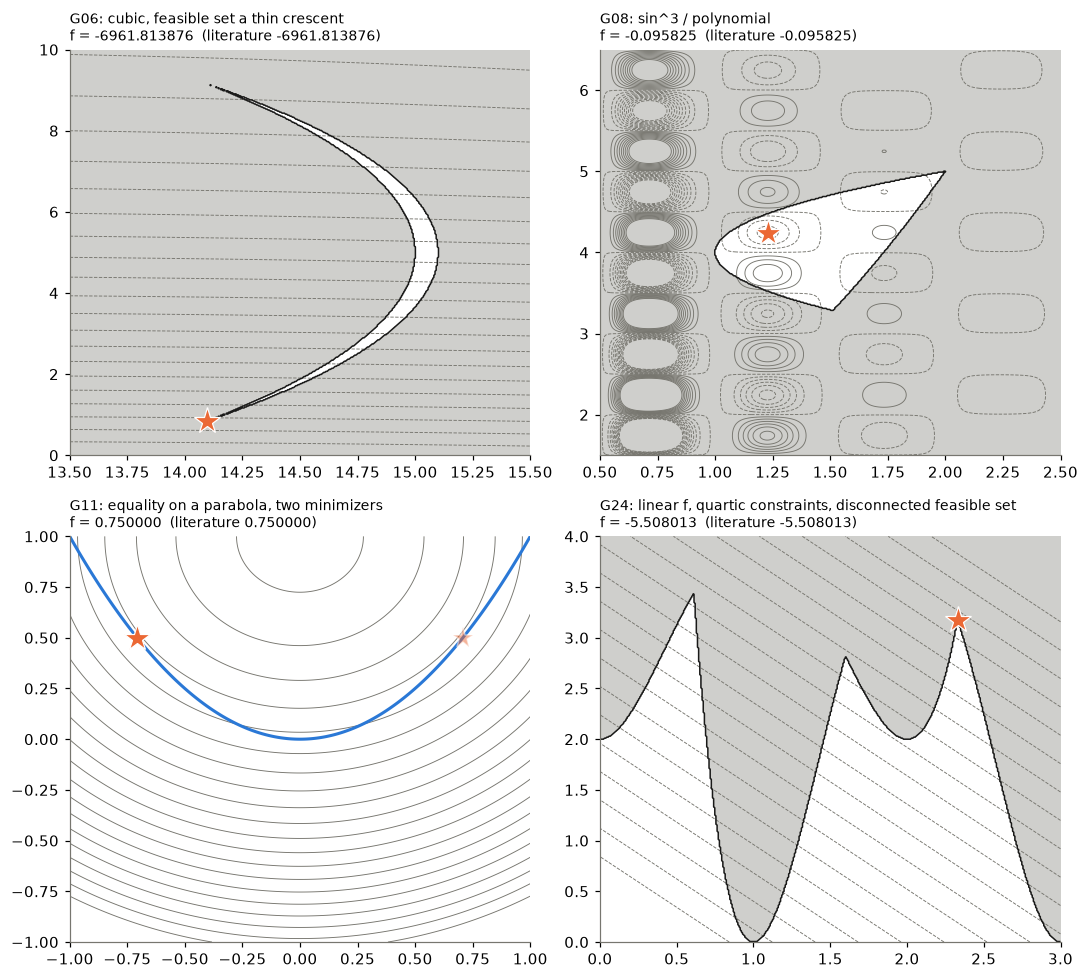

In [9]:
views = {"G06": ([13.5, 15.5], [0, 10]), "G08": ([0.5, 2.5], [1.5, 6.5]),
         "G11": ([-1, 1], [-1, 1]), "G24": ([0, 3], [0, 4])}
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for ax, (name, (xr, yr)) in zip(axes.ravel(), views.items()):
    p, r = C[name], cresults[name]
    A, B = np.meshgrid(np.linspace(*xr, 400), np.linspace(*yr, 400))
    XY = jnp.asarray(np.c_[A.ravel(), B.ravel()])
    Z = np.asarray(jax.vmap(p.f)(XY)).reshape(A.shape)
    zlo, zhi = np.quantile(Z, [0.03, 0.97])  # clip extreme values (G08 is singular near x = 0)
    ax.contour(A, B, Z, levels=np.linspace(zlo, zhi, 20), colors=MUTED, linewidths=0.6)
    if p.ineq is not None:
        G = np.asarray(jax.vmap(p.ineq)(XY)).reshape(A.shape + (-1,))
        infeasible = (G > 0).any(axis=-1)
        ax.contourf(A, B, infeasible.astype(float), levels=[0.5, 1.5], colors=[MUTED], alpha=0.35)
        ax.contour(A, B, infeasible.astype(float), levels=[0.5], colors=INK, linewidths=1)
    if p.eq is not None:
        H = np.asarray(jax.vmap(p.eq)(XY)).reshape(A.shape)
        ax.contour(A, B, H, levels=[0], colors=BLUE, linewidths=2)
        # G11 has two minimizers, symmetric in x
        ax.plot(-r.x[0], r.x[1], "*", ms=14, color=ORANGE, mec="white", alpha=0.5)
    ax.plot(*r.x, "*", ms=18, color=ORANGE, mec="white", mew=0.8)
    ax.set_xlim(xr); ax.set_ylim(yr); ax.grid(False)
    ax.set_title(f"{name}: {p.note}\nf = {r.fun:.6f}  (literature {p.fstar:.6f})", loc="left", fontsize=9)
fig.tight_layout()

G06's feasible set (white) is a thin crescent between two circles, shown here
zoomed in; the optimum is at its tip. G08's is a small lens between two
parabolas. G11's is the parabola $y=x^2$ itself (blue), an equality
constraint, with two symmetric minimizers. G24's consists of pieces that
touch only at isolated points on the lower edge, such as $(1, 0)$; the optimum
is at the tip of the right-hand piece, where the two quartic constraints meet.

The full table, including the three larger problems (G04, the Haverly pooling
problem and the reactor network):

In [10]:
ctable.style.format({"f_lit": "{:.6f}", "f_found": "{:.6f}", "L": "{:.6f}", "time_s": "{:.1f}",
                     "max_violation": "{:.1e}"})

,n,ineq,eq,f_lit,f_found,L,nodes,time_s,status,verified,max_violation,note
problem,,,,,,,,,,,,
G06,2,2,0,-6961.813876,-6961.813876,-6961.817313,11,2.7,optimal,True,0.0e+00,"cubic, feasible set a thin crescent"
G08,2,2,0,-0.095825,-0.095825,-0.095828,19,4.8,optimal,True,0.0e+00,sin^3 / polynomial
G11,2,0,1,0.750000,0.750000,0.749999,7,0.8,optimal,True,5.6e-17,"equality on a parabola, two minimizers"
G24,2,2,0,-5.508013,-5.508013,-5.508016,43,1.5,optimal,True,0.0e+00,"linear f, quartic constraints, disconnected feasible set"
G04,5,6,0,-30665.538672,-30665.538672,-30665.561787,13,5.0,optimal,True,0.0e+00,"5-D, bilinear double-sided constraints"
haverly,9,2,4,-400.000000,-400.000019,-400.000115,17,4.9,optimal,True,9.1e-07,"9-D pooling, bilinear equalities"
reactor,6,1,4,-0.388811,-0.388811,-0.388821,159,5.0,optimal,True,7.1e-15,"6-D reactor network, sqrt + bilinear equalities"


In [11]:
print(f"all {len(ctable)} constrained problems optimal and verified: "
      f"{((ctable.status == 'optimal') & ctable.verified).all()}")
print(f"largest constraint violation: {ctable.max_violation.max():.1e}")

all 7 constrained problems optimal and verified: True
largest constraint violation: 9.1e-07


## Summary

* All problems are written as plain JAX functions, including nonsmooth
  pieces (`where`, `abs`, `max`), a neural network, and loops over `arange`.
* Plain interval bounds and local multistart are not enough on most of them:
  the root bounds are far from $f^*$ and many local runs end in the wrong
  minimum.
* jaxglobal solves every problem to a certified gap with the same default
  settings, and the constrained solutions are re-checked for feasibility in
  float64.

In [12]:
# Save both tables for the README.
out = {"unconstrained": table.reset_index().to_dict("records"),
       "constrained": ctable.drop(columns="note").reset_index().to_dict("records")}
(ROOT / "notebooks" / "results" / "test_problems_results.json").write_text(json.dumps(out, indent=1, default=float))

6157